In [68]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.linear_model import LogisticRegression

# Dataset Understanding

In [69]:
lung_cancer = pd.read_csv("lcs.csv")
lung_cancer.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [70]:
lung_cancer.describe()

,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
count,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000
mean,50.750216,1.317200,1.339672,1.504754,1.332757,1.322385,1.458946,1.535869,1.336214,1.597234,1.509939,1.337943,1.292135,1.315471
std,17.183339,0.465587,0.473803,0.500194,0.471404,0.467592,0.498527,0.498927,0.472618,0.490666,0.500117,0.473214,0.454941,0.464904
min,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,35.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,54.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,2.000000,1.000000,1.000000,1.000000
75%,64.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,87.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


In [71]:
lung_cancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 1157 entries, 0 to 1156
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 1157 non-null   str  
 1   AGE                    1157 non-null   int64
 2   SMOKING                1157 non-null   int64
 3   YELLOW_FINGERS         1157 non-null   int64
 4   ANXIETY                1157 non-null   int64
 5   PEER_PRESSURE          1157 non-null   int64
 6   CHRONIC DISEASE        1157 non-null   int64
 7   FATIGUE                1157 non-null   int64
 8   ALLERGY                1157 non-null   int64
 9   WHEEZING               1157 non-null   int64
 10  ALCOHOL CONSUMING      1157 non-null   int64
 11  COUGHING               1157 non-null   int64
 12  SHORTNESS OF BREATH    1157 non-null   int64
 13  SWALLOWING DIFFICULTY  1157 non-null   int64
 14  CHEST PAIN             1157 non-null   int64
 15  LUNG_CANCER            1157 non-null   str  
dtyp

In [72]:
print(lung_cancer.columns.tolist())

['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']


In [73]:
#Clean the column names spaces 
lung_cancer.columns = lung_cancer.columns.str.strip()
print(lung_cancer.columns.tolist())

['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']


# Data Analysis

In [74]:
# Count missing values in each column
missing_values = lung_cancer.isnull().sum()

print(missing_values)

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64


In [75]:
missing = lung_cancer.isnull().sum()

missing_percentage = (lung_cancer.isnull().sum() / len(lung_cancer)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percentage
})

print(missing_report)

                       Missing Count  Missing Percentage
GENDER                             0                 0.0
AGE                                0                 0.0
SMOKING                            0                 0.0
YELLOW_FINGERS                     0                 0.0
ANXIETY                            0                 0.0
PEER_PRESSURE                      0                 0.0
CHRONIC DISEASE                    0                 0.0
FATIGUE                            0                 0.0
ALLERGY                            0                 0.0
WHEEZING                           0                 0.0
ALCOHOL CONSUMING                  0                 0.0
COUGHING                           0                 0.0
SHORTNESS OF BREATH                0                 0.0
SWALLOWING DIFFICULTY              0                 0.0
CHEST PAIN                         0                 0.0
LUNG_CANCER                        0                 0.0


In [76]:
#Checking the duplicate rows 

print("Duplicate Rows: {0}".format(lung_cancer.duplicated().sum()))

Duplicate Rows: 246


In [77]:
print(lung_cancer[lung_cancer.duplicated()])

    GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
99       M   56        2               1        1              1   
100      M   58        2               1        1              1   
117      F   51        2               2        2              2   
199      F   55        2               1        1              2   
212      M   58        2               1        1              1   
..     ...  ...      ...             ...      ...            ...   
903      F   74        1               1        2              1   
904      F   74        1               1        2              1   
907      F   79        1               1        2              1   
908      F   79        1               1        2              1   
909      F   79        1               1        2              1   

     CHRONIC DISEASE  FATIGUE  ALLERGY  WHEEZING  ALCOHOL CONSUMING  COUGHING  \
99                 1        2        2         2                  2         2   
100                1 

# Observation

The dataset contains 246 duplicate rows.I observed that the duplicated records have the same feature values.These repeated records may represent different patients having similar characteristics.I believe retaining these records will be useful for the classification analysis. I am not planning to remove the duplicate records from the dataset.

In [78]:
duplicate_count = lung_cancer.duplicated().sum()

print("Duplicate records:", duplicate_count)


duplicate_records = lung_cancer[lung_cancer.duplicated(keep=False)]

print(duplicate_records.sort_values(by=lung_cancer.columns.tolist()))

Duplicate records: 246
    GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
761      F   21        1               1        1              1   
762      F   21        1               1        1              1   
763      F   21        1               1        1              1   
764      F   21        1               1        1              1   
765      F   21        1               1        1              1   
..     ...  ...      ...             ...      ...            ...   
290      M   76        2               1        1              1   
755      M   79        1               1        2              1   
756      M   79        1               1        2              1   
757      M   79        1               1        2              1   
758      M   79        1               1        2              1   

     CHRONIC DISEASE  FATIGUE  ALLERGY  WHEEZING  ALCOHOL CONSUMING  COUGHING  \
761                1        1        1         1                  2         2  

In [79]:
# Find the frequency of each unique complete record
duplicate_groups = (lung_cancer.groupby(lung_cancer.columns.tolist()).size().reset_index(name="Frequency"))

# Display only repeated records
duplicate_groups = duplicate_groups[duplicate_groups["Frequency"] > 1]

print(duplicate_groups.sort_values( by="Frequency",ascending=False))

print("Unique repeated patterns:", len(duplicate_groups))
print("Total duplicate occurrences:", lung_cancer.duplicated().sum())

    GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
3        F   21        1               1        1              1   
437      M   21        1               1        1              1   
648      M   54        1               1        1              1   
200      F   54        1               1        1              1   
151      F   46        1               1        1              1   
..     ...  ...      ...             ...      ...            ...   
534      M   35        2               2        2              2   
75       F   32        2               2        2              2   
608      M   47        2               2        2              2   
278      F   61        1               2        2              2   
627      M   51        1               2        1              1   

     CHRONIC DISEASE  FATIGUE  ALLERGY  WHEEZING  ALCOHOL CONSUMING  COUGHING  \
3                  1        1        1         1                  2         2   
437                1 

In [80]:
# Separate input features and target
feature_columns = [column for column in lung_cancer.columns if column != "LUNG_CANCER"]

# Count unique target labels for each feature combination
label_variations = (lung_cancer.groupby(feature_columns)["LUNG_CANCER"].nunique())

# Identify feature combinations with conflicting labels
conflicting_profiles = label_variations[label_variations > 1]

print("Conflicting feature profiles:",len(conflicting_profiles))

Conflicting feature profiles: 51


In [81]:
# Get all records belonging to conflicting profiles
conflicting_records = lung_cancer.merge( conflicting_profiles.reset_index()[feature_columns],on=feature_columns,how="inner")

conflicting_records.head(20)

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,64,2,1,1,1,1,1,2,2,2,2,1,1,2,YES
1,M,64,2,1,1,1,1,1,2,2,2,2,1,1,2,NO
2,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,YES
3,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO
4,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO
5,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO
6,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO
7,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO
8,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO
9,M,21,1,1,1,1,1,1,1,1,2,2,1,1,1,NO


# Observation
The dataset contains 246 duplicate rows.I observed that the duplicated records have the same feature values.These repeated records may represent different patients having similar characteristics.I believe retaining these records will be useful for the classification analysis. I am not planning to remove the duplicate records from the dataset.

# Exploratory Data Analysis

# Univarient Analysis

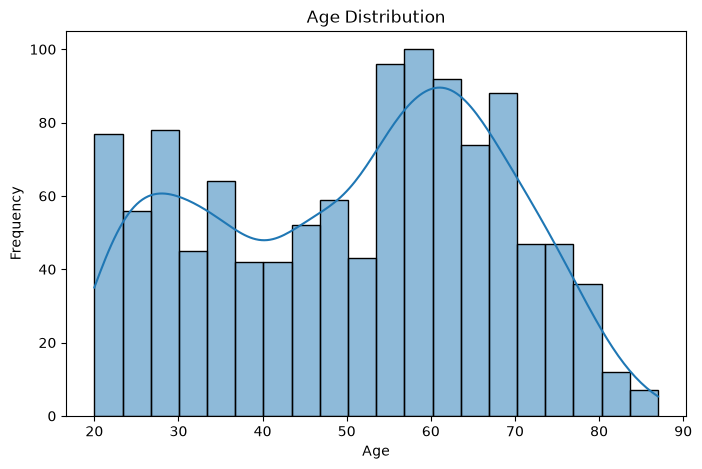

In [82]:
plt.figure(figsize=(8, 5))
sns.histplot(data=lung_cancer, x="AGE", bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

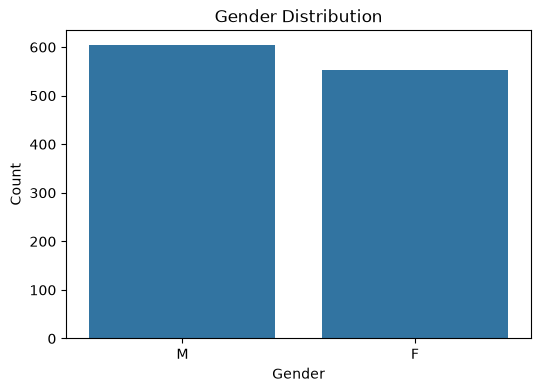

In [83]:
plt.figure(figsize=(6, 4))
sns.countplot(data=lung_cancer, x="GENDER")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

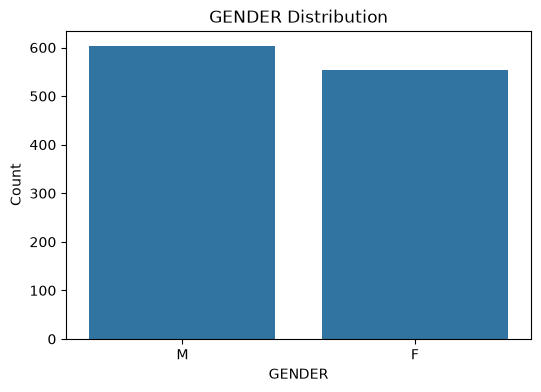

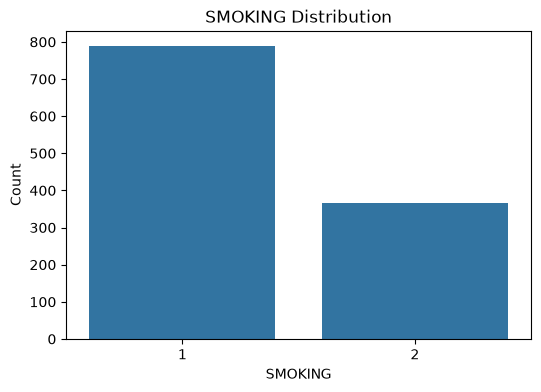

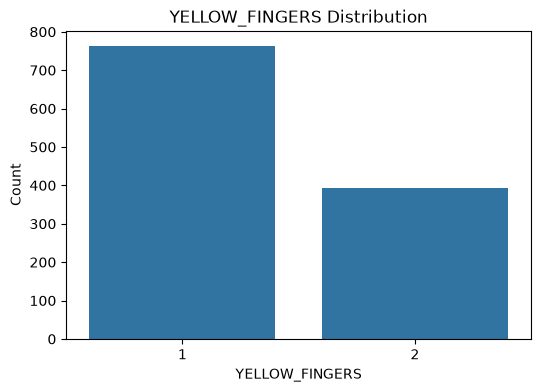

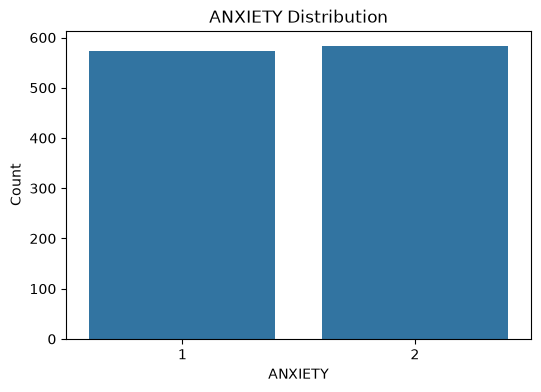

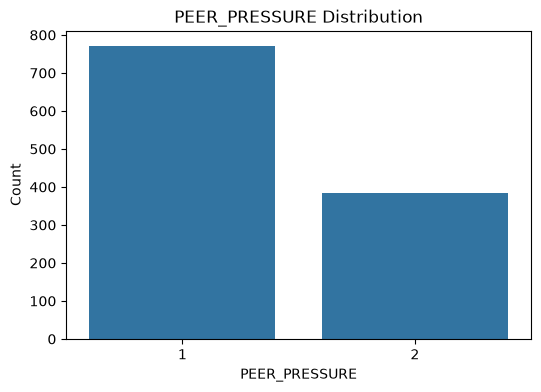

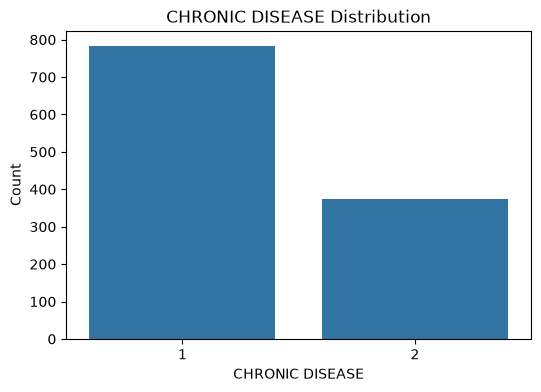

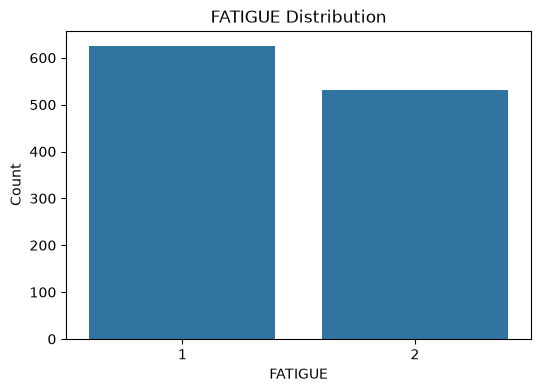

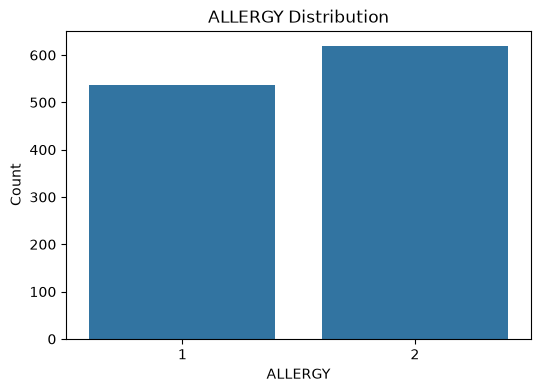

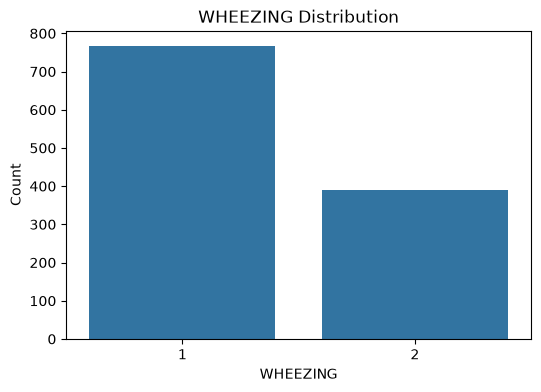

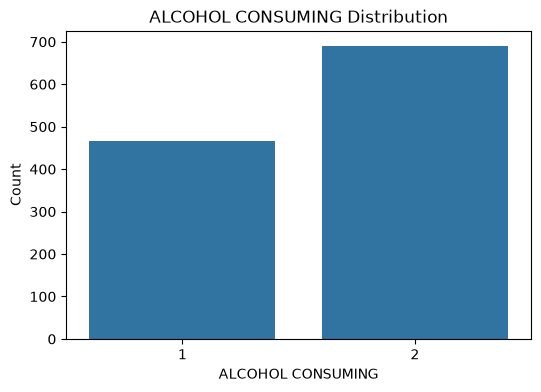

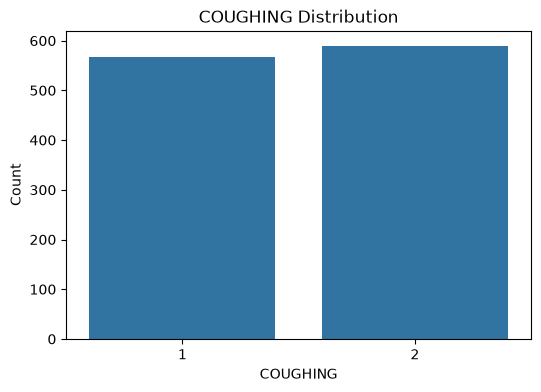

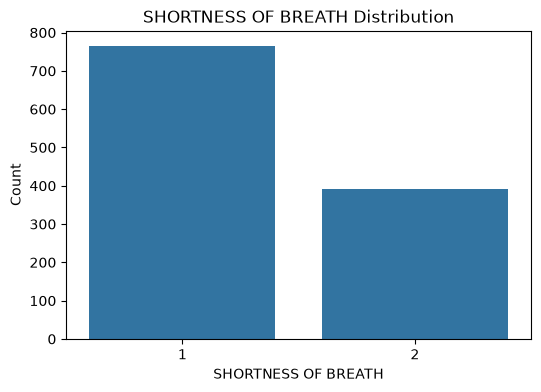

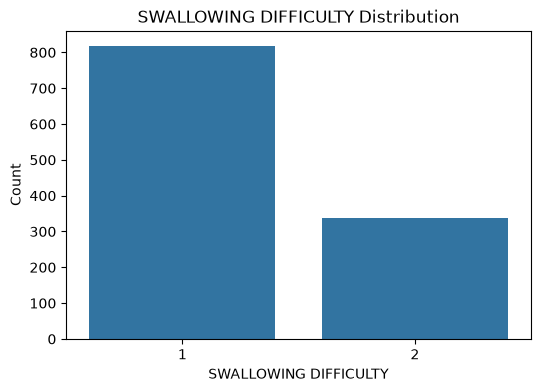

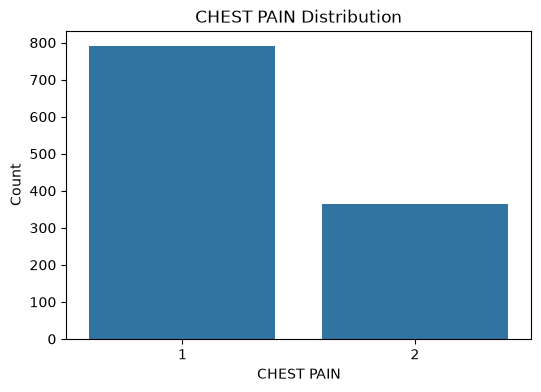

In [84]:
categorical_features = [column for column in lung_cancer.columns if column not in ["AGE", "LUNG_CANCER"]]

for feature in categorical_features:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=lung_cancer, x=feature)
    plt.title(f"{feature} Distribution")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.show()

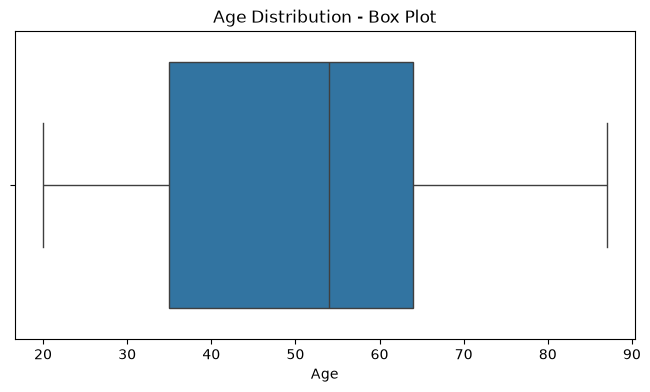

In [85]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=lung_cancer, x="AGE")
plt.title("Age Distribution - Box Plot")
plt.xlabel("Age")
plt.show()

In [86]:
age_statistics = lung_cancer["AGE"].describe()
print(age_statistics)

count    1157.000000
mean       50.750216
std        17.183339
min        20.000000
25%        35.000000
50%        54.000000
75%        64.000000
max        87.000000
Name: AGE, dtype: float64


# Observations:
- The AGE histogram shows how the age values are distributed in the dataset.
- The GENDER count plot helps me understand the distribution of male and female records.
- The categorical feature plots help me understand the distribution of each feature.
- The AGE box plot helps me identify the spread of age values and possible outliers.
- The descriptive statistics provide details such as mean, minimum, maximum, and standard deviation.

Overall, I used univariate analysis to understand each feature individually before analysing the relationship between features.

# Bivariate EDA

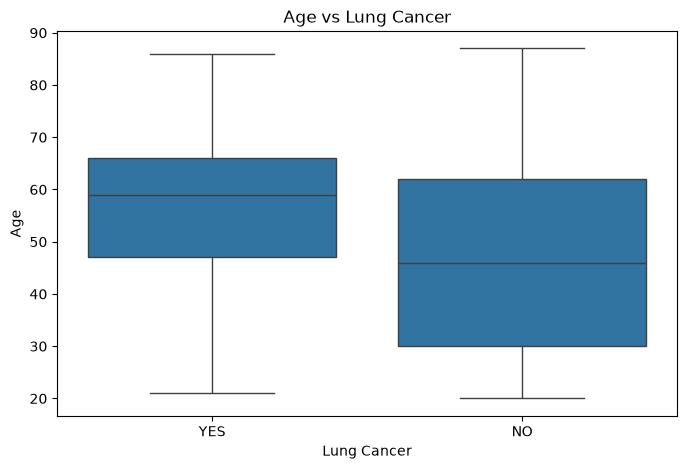

In [87]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=lung_cancer, x="LUNG_CANCER", y="AGE")
plt.title("Age vs Lung Cancer")
plt.xlabel("Lung Cancer")
plt.ylabel("Age")
plt.show()

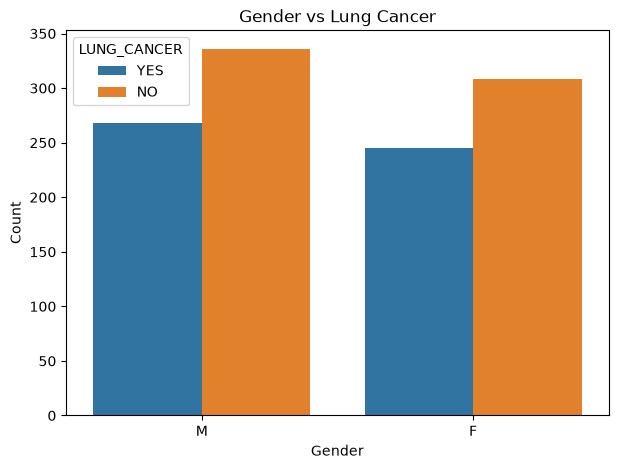

In [88]:
plt.figure(figsize=(7, 5))
sns.countplot(data=lung_cancer, x="GENDER", hue="LUNG_CANCER")
plt.title("Gender vs Lung Cancer")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

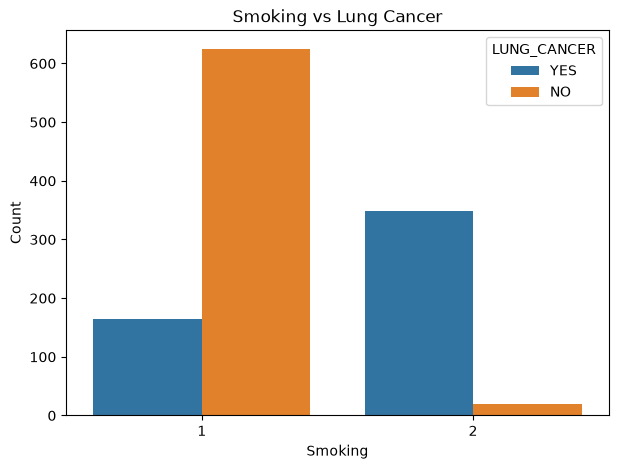

In [89]:
plt.figure(figsize=(7, 5))
sns.countplot(data=lung_cancer, x="SMOKING", hue="LUNG_CANCER")
plt.title("Smoking vs Lung Cancer")
plt.xlabel("Smoking")
plt.ylabel("Count")
plt.show()

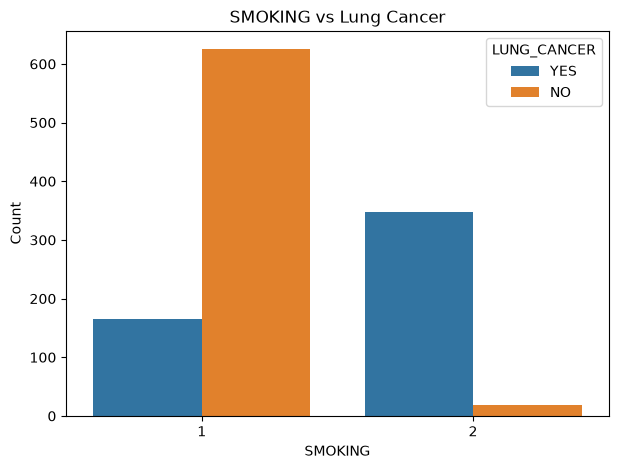

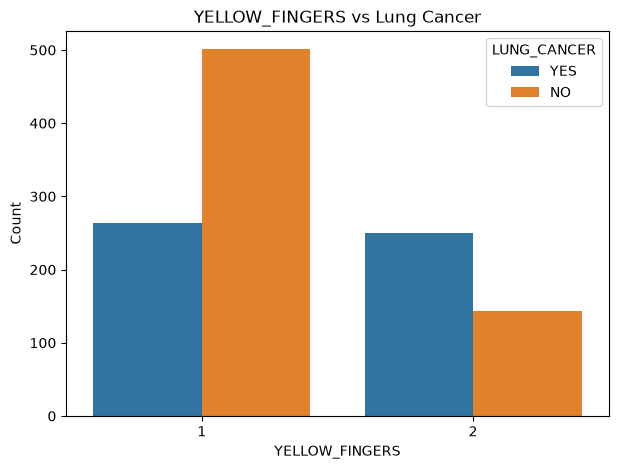

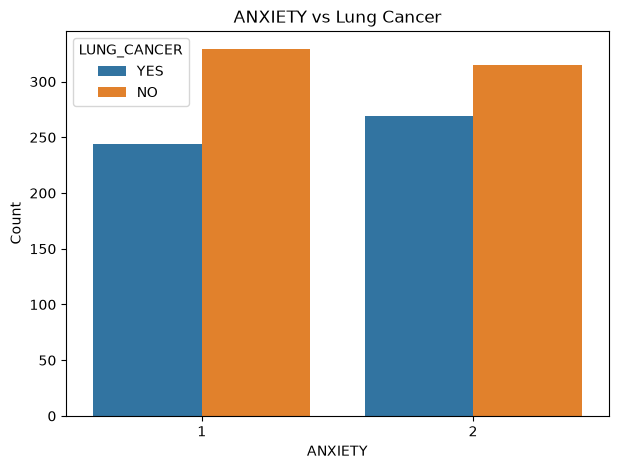

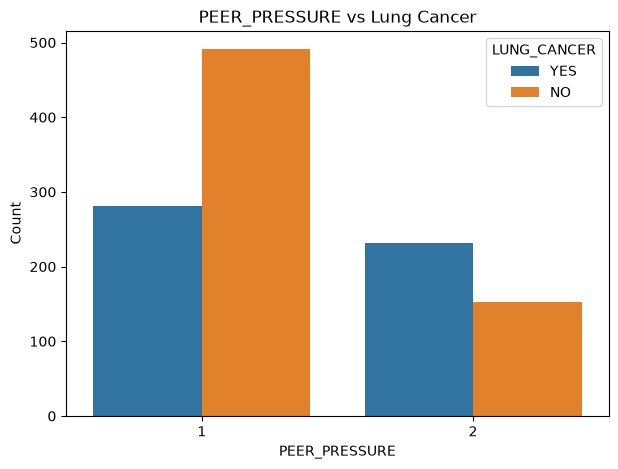

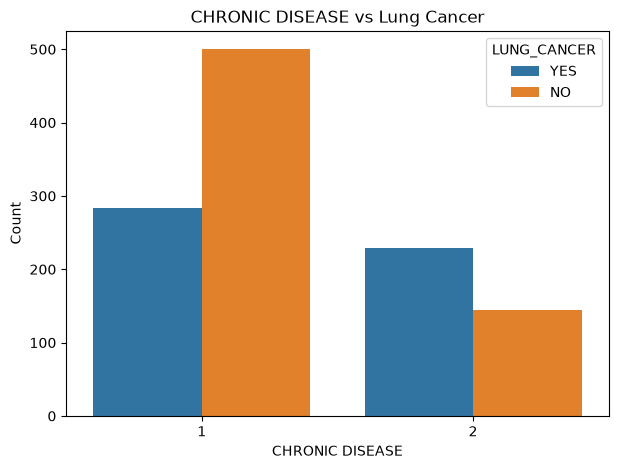

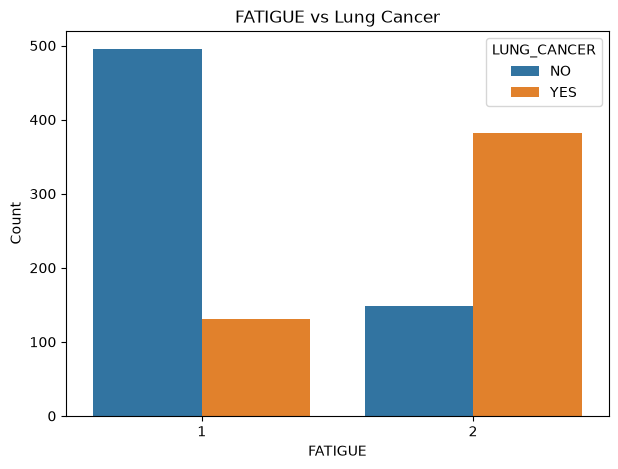

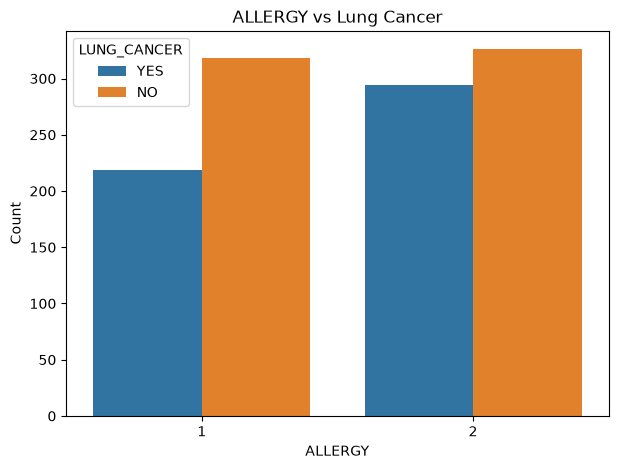

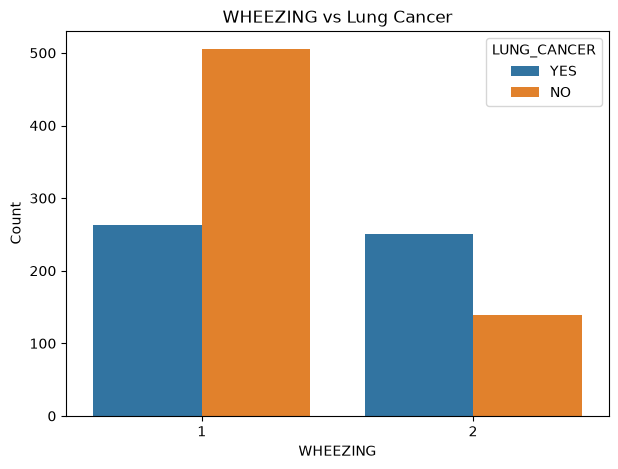

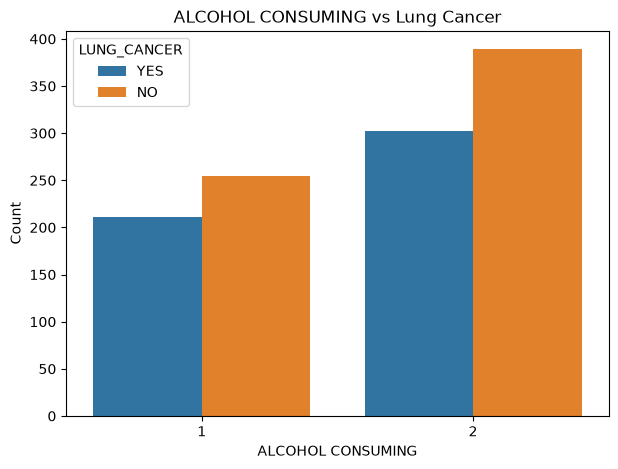

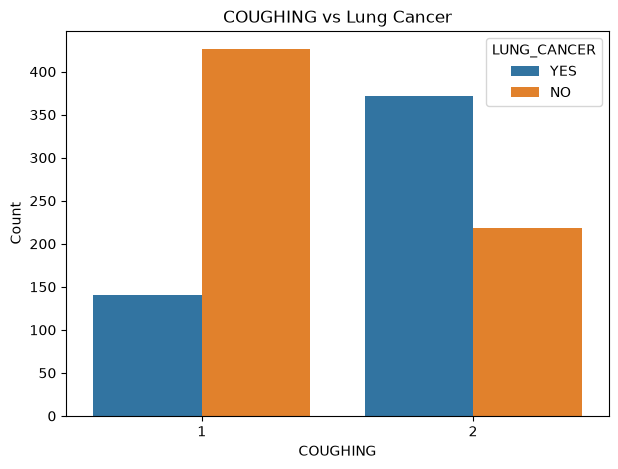

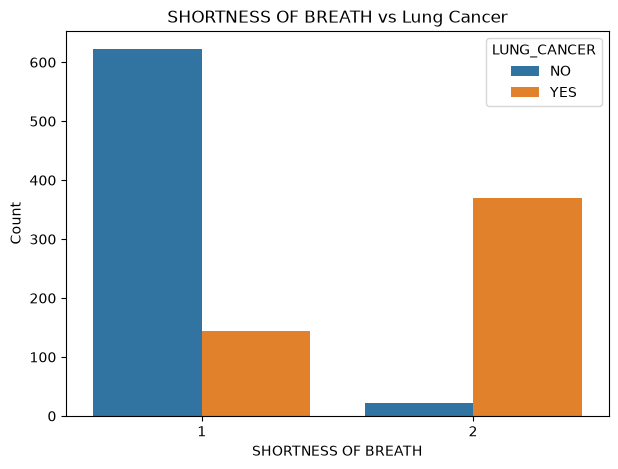

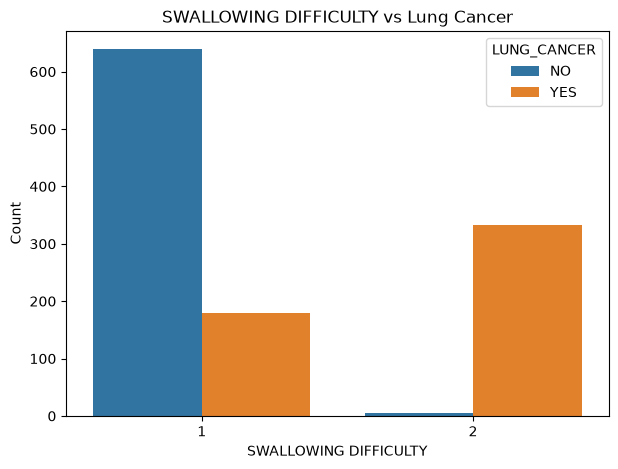

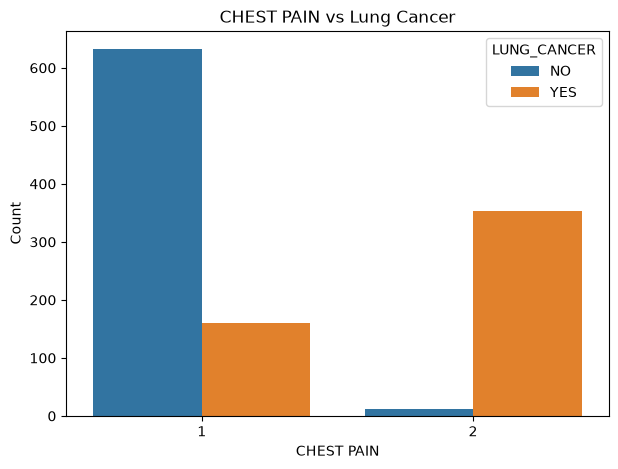

In [90]:
categorical_features = [column for column in lung_cancer.columns if column not in ["AGE", "GENDER", "LUNG_CANCER"]]

for feature in categorical_features:
    plt.figure(figsize=(7, 5))
    sns.countplot(data=lung_cancer, x=feature, hue="LUNG_CANCER")
    plt.title(f"{feature} vs Lung Cancer")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.show()

I compared the AGE feature with the lung cancer target to understand the age distribution across both groups.
I compared the GENDER feature to understand how male and female records are distributed across the target classes.
I analysed the SMOKING feature to check how smoking status is distributed between YES and NO.
I compared the remaining categorical features with the target to identify any differences in their distributions.
These plots help me understand the relationship between individual features and the lung cancer target.

# Data Preprocessing

In [91]:
lung_cancer.dtypes

GENDER                     str
AGE                      int64
SMOKING                  int64
YELLOW_FINGERS           int64
ANXIETY                  int64
PEER_PRESSURE            int64
CHRONIC DISEASE          int64
FATIGUE                  int64
ALLERGY                  int64
WHEEZING                 int64
ALCOHOL CONSUMING        int64
COUGHING                 int64
SHORTNESS OF BREATH      int64
SWALLOWING DIFFICULTY    int64
CHEST PAIN               int64
LUNG_CANCER                str
dtype: object

In [92]:
for column in lung_cancer.columns:
    print(f"{column}: {lung_cancer[column].unique()}")

GENDER: <StringArray>
['M', 'F']
Length: 2, dtype: str
AGE: [69 74 59 63 75 52 51 68 53 61 72 60 58 48 57 44 64 21 65 55 62 56 67 77
 70 54 49 73 47 71 66 76 78 81 79 38 39 87 46 35 82 32 43 86 20 22 23 24
 25 26 27 28 29 30 31 33 34 36 37 40 41 42 45 50 80 83 84 85]
SMOKING: [1 2]
YELLOW_FINGERS: [2 1]
ANXIETY: [2 1]
PEER_PRESSURE: [1 2]
CHRONIC DISEASE: [1 2]
FATIGUE: [2 1]
ALLERGY: [1 2]
WHEEZING: [2 1]
ALCOHOL CONSUMING: [2 1]
COUGHING: [2 1]
SHORTNESS OF BREATH: [2 1]
SWALLOWING DIFFICULTY: [2 1]
CHEST PAIN: [2 1]
LUNG_CANCER: <StringArray>
['YES', 'NO']
Length: 2, dtype: str


In [93]:
categorical_features = lung_cancer.select_dtypes(include=["object"]).columns.tolist()

print(categorical_features)

['GENDER', 'LUNG_CANCER']


/var/folders/m9/65482h010qs6_yq0cg9q_hg40000gp/T/ipykernel_82905/1362693984.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = lung_cancer.select_dtypes(include=["object"]).columns.tolist()


In [94]:
from sklearn.preprocessing import LabelEncoder

lung_cancer_encoded = lung_cancer.copy()

label_encoders = {}

for feature in categorical_features:
    label_encoders[feature] = LabelEncoder()
    lung_cancer_encoded[feature] = label_encoders[feature].fit_transform(lung_cancer_encoded[feature])

In [95]:
lung_cancer_encoded.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,1
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,1
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,0
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,0
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,0


In [96]:
lung_cancer_encoded.dtypes

GENDER                   int64
AGE                      int64
SMOKING                  int64
YELLOW_FINGERS           int64
ANXIETY                  int64
PEER_PRESSURE            int64
CHRONIC DISEASE          int64
FATIGUE                  int64
ALLERGY                  int64
WHEEZING                 int64
ALCOHOL CONSUMING        int64
COUGHING                 int64
SHORTNESS OF BREATH      int64
SWALLOWING DIFFICULTY    int64
CHEST PAIN               int64
LUNG_CANCER              int64
dtype: object

# Split Features and Target Variables 

In [97]:
X = lung_cancer_encoded.drop(columns=["LUNG_CANCER"])
y = lung_cancer_encoded["LUNG_CANCER"]

In [98]:
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1157, 15)
Target shape: (1157,)


In [99]:
print("Input features:")
X.head()

Input features:


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1


In [100]:
print("Target:")
y.head()

Target:


0    1
1    1
2    0
3    0
4    0
Name: LUNG_CANCER, dtype: int64

In [101]:
from sklearn.model_selection import StratifiedGroupKFold

feature_groups = X.astype(str).agg("_".join, axis=1)

data_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_indices, test_indices = next(data_splitter.split(X, y, groups=feature_groups))

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]
y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

In [102]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (915, 15)
Testing features: (242, 15)
Training target: (915,)
Testing target: (242,)


In [103]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("Testing target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
LUNG_CANCER
0    54.644809
1    45.355191
Name: proportion, dtype: float64
Testing target distribution:
LUNG_CANCER
0    59.504132
1    40.495868
Name: proportion, dtype: float64


In [104]:
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)

In [105]:
print("Original training data:")
display(X_train.head())

print("Scaled training data:")
display(pd.DataFrame(X_train_scaled, columns=X_train.columns).head())

Original training data:


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1
6,1,52,2,1,1,1,1,2,1,2,2,2,2,1,2
7,0,51,2,2,2,2,1,2,2,1,1,1,2,2,1


Scaled training data:


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
0,0.951972,1.054512,-0.696699,1.386839,1.001093,-0.698430,-0.676022,1.062030,-1.045859,1.424711,0.863819,0.975172,1.340957,1.502074,1.449722
1,0.951972,0.699212,1.435340,1.386839,1.001093,-0.698430,-0.676022,-0.941593,-1.045859,-0.701897,0.863819,-1.025461,-0.745736,1.502074,1.449722
2,-1.050451,0.699212,-0.696699,1.386839,-0.998908,-0.698430,-0.676022,-0.941593,-1.045859,1.424711,-1.157650,0.975172,1.340957,-0.665746,-0.689787
3,0.951972,0.047826,1.435340,-0.721064,-0.998908,-0.698430,-0.676022,1.062030,-1.045859,1.424711,0.863819,0.975172,1.340957,-0.665746,1.449722
4,-1.050451,-0.011390,1.435340,1.386839,1.001093,1.431782,-0.676022,1.062030,0.956152,-0.701897,-1.157650,-1.025461,1.340957,1.502074,-0.689787


# Model Training

In [106]:
from sklearn.linear_model import LogisticRegression
logistic_regression_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_regression_model.fit(X_train_scaled, y_train)
logistic_regression_predictions = logistic_regression_model.predict(X_test_scaled)

In [107]:
print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(logistic_regression_predictions[:10])

Actual values:
[1 0 1 1 1 1 1 1 1 1]
Predicted values:
[1 1 1 1 1 1 1 1 1 0]


In [108]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)
decision_tree_predictions = decision_tree_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(decision_tree_predictions[:10])

Actual values:
[1 0 1 1 1 1 1 1 1 1]
Predicted values:
[1 1 1 1 1 1 1 1 1 1]


In [109]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_test_scaled)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(knn_predictions[:10])

Actual values:
[1 0 1 1 1 1 1 1 1 1]
Predicted values:
[1 1 1 1 1 1 1 1 1 1]


In [110]:
from sklearn.naive_bayes import GaussianNB

naive_bayes_model = GaussianNB()
naive_bayes_model.fit(X_train, y_train)
naive_bayes_predictions = naive_bayes_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(naive_bayes_predictions[:10])

Actual values:
[1 0 1 1 1 1 1 1 1 1]
Predicted values:
[1 1 1 1 1 1 1 1 1 1]


In [111]:
from sklearn.svm import SVC

svm_model = SVC(kernel="rbf", probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(svm_predictions[:10])

Actual values:
[1 0 1 1 1 1 1 1 1 1]
Predicted values:
[1 1 1 1 1 1 1 1 1 1]


# Model Evaluation

In [112]:
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef

In [113]:
logistic_regression_accuracy = accuracy_score(y_test, logistic_regression_predictions)
logistic_regression_auc = roc_auc_score(y_test, logistic_regression_model.predict_proba(X_test_scaled)[:, 1])
logistic_regression_precision = precision_score(y_test, logistic_regression_predictions)
logistic_regression_recall = recall_score(y_test, logistic_regression_predictions)
logistic_regression_f1 = f1_score(y_test, logistic_regression_predictions)
logistic_regression_mcc = matthews_corrcoef(y_test, logistic_regression_predictions)

print("Logistic Regression Results")
print("Accuracy:", logistic_regression_accuracy)
print("AUC:", logistic_regression_auc)
print("Precision:", logistic_regression_precision)
print("Recall:", logistic_regression_recall)
print("F1 Score:", logistic_regression_f1)
print("MCC:", logistic_regression_mcc)

Logistic Regression Results
Accuracy: 0.8884297520661157
AUC: 0.9452947845804989
Precision: 0.961038961038961
Recall: 0.7551020408163265
F1 Score: 0.8457142857142858
MCC: 0.7738592344053544


In [114]:
decision_tree_accuracy = accuracy_score(y_test, decision_tree_predictions)
decision_tree_auc = roc_auc_score(y_test, decision_tree_model.predict_proba(X_test)[:, 1])
decision_tree_precision = precision_score(y_test, decision_tree_predictions)
decision_tree_recall = recall_score(y_test, decision_tree_predictions)
decision_tree_f1 = f1_score(y_test, decision_tree_predictions)
decision_tree_mcc = matthews_corrcoef(y_test, decision_tree_predictions)

print("Decision Tree Results")
print("Accuracy:", decision_tree_accuracy)
print("AUC:", decision_tree_auc)
print("Precision:", decision_tree_precision)
print("Recall:", decision_tree_recall)
print("F1 Score:", decision_tree_f1)
print("MCC:", decision_tree_mcc)

Decision Tree Results
Accuracy: 0.9173553719008265
AUC: 0.9328939909297052
Precision: 0.9534883720930233
Recall: 0.8367346938775511
F1 Score: 0.8913043478260869
MCC: 0.8296752816087556


In [115]:
knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_auc = roc_auc_score(y_test, knn_model.predict_proba(X_test_scaled)[:, 1])
knn_precision = precision_score(y_test, knn_predictions)
knn_recall = recall_score(y_test, knn_predictions)
knn_f1 = f1_score(y_test, knn_predictions)
knn_mcc = matthews_corrcoef(y_test, knn_predictions)

print("KNN Results")
print("Accuracy:", knn_accuracy)
print("AUC:", knn_auc)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1 Score:", knn_f1)
print("MCC:", knn_mcc)

KNN Results
Accuracy: 0.9256198347107438
AUC: 0.9621952947845804
Precision: 0.9651162790697675
Recall: 0.8469387755102041
F1 Score: 0.9021739130434783
MCC: 0.8472630021894598


In [116]:
naive_bayes_accuracy = accuracy_score(y_test, naive_bayes_predictions)
naive_bayes_auc = roc_auc_score(y_test, naive_bayes_model.predict_proba(X_test)[:, 1])
naive_bayes_precision = precision_score(y_test, naive_bayes_predictions)
naive_bayes_recall = recall_score(y_test, naive_bayes_predictions)
naive_bayes_f1 = f1_score(y_test, naive_bayes_predictions)
naive_bayes_mcc = matthews_corrcoef(y_test, naive_bayes_predictions)

print("Gaussian Naive Bayes Results")
print("Accuracy:", naive_bayes_accuracy)
print("AUC:", naive_bayes_auc)
print("Precision:", naive_bayes_precision)
print("Recall:", naive_bayes_recall)
print("F1 Score:", naive_bayes_f1)
print("MCC:", naive_bayes_mcc)

Gaussian Naive Bayes Results
Accuracy: 0.9090909090909091
AUC: 0.8949829931972789
Precision: 0.9130434782608695
Recall: 0.8571428571428571
F1 Score: 0.8842105263157894
MCC: 0.8105980774441792


In [117]:
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_auc = roc_auc_score(y_test, svm_model.predict_proba(X_test_scaled)[:, 1])
svm_precision = precision_score(y_test, svm_predictions)
svm_recall = recall_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions)
svm_mcc = matthews_corrcoef(y_test, svm_predictions)

print("SVM Results")
print("Accuracy:", svm_accuracy)
print("AUC:", svm_auc)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)
print("MCC:", svm_mcc)

SVM Results
Accuracy: 0.9380165289256198
AUC: 0.9580498866213152
Precision: 0.9662921348314607
Recall: 0.8775510204081632
F1 Score: 0.9197860962566845
MCC: 0.8721502271438724


In [118]:
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_auc = roc_auc_score(y_test, svm_model.predict_proba(X_test_scaled)[:, 1])
svm_precision = precision_score(y_test, svm_predictions)
svm_recall = recall_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions)
svm_mcc = matthews_corrcoef(y_test, svm_predictions)

print("SVM Results")
print("Accuracy:", svm_accuracy)
print("AUC:", svm_auc)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)
print("MCC:", svm_mcc)

SVM Results
Accuracy: 0.9380165289256198
AUC: 0.9580498866213152
Precision: 0.9662921348314607
Recall: 0.8775510204081632
F1 Score: 0.9197860962566845
MCC: 0.8721502271438724


In [119]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "KNN", "Gaussian Naive Bayes", "SVM"],
    "Accuracy": [logistic_regression_accuracy, decision_tree_accuracy, knn_accuracy, naive_bayes_accuracy, svm_accuracy],
    "AUC": [logistic_regression_auc, decision_tree_auc, knn_auc, naive_bayes_auc, svm_auc],
    "Precision": [logistic_regression_precision, decision_tree_precision, knn_precision, naive_bayes_precision, svm_precision],
    "Recall": [logistic_regression_recall, decision_tree_recall, knn_recall, naive_bayes_recall, svm_recall],
    "F1 Score": [logistic_regression_f1, decision_tree_f1, knn_f1, naive_bayes_f1, svm_f1],
    "MCC": [logistic_regression_mcc, decision_tree_mcc, knn_mcc, naive_bayes_mcc, svm_mcc]
})

model_comparison

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.888430,0.945295,0.961039,0.755102,0.845714,0.773859
1,Decision Tree,0.917355,0.932894,0.953488,0.836735,0.891304,0.829675
2,KNN,0.925620,0.962195,0.965116,0.846939,0.902174,0.847263
3,Gaussian Naive Bayes,0.909091,0.894983,0.913043,0.857143,0.884211,0.810598
4,SVM,0.938017,0.958050,0.966292,0.877551,0.919786,0.872150


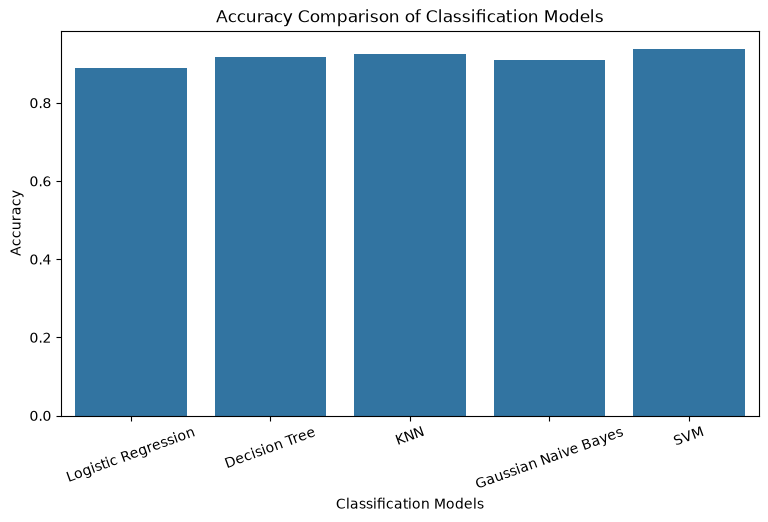

In [120]:
plt.figure(figsize=(9, 5))
sns.barplot(data=model_comparison, x="Model", y="Accuracy")
plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

In [121]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

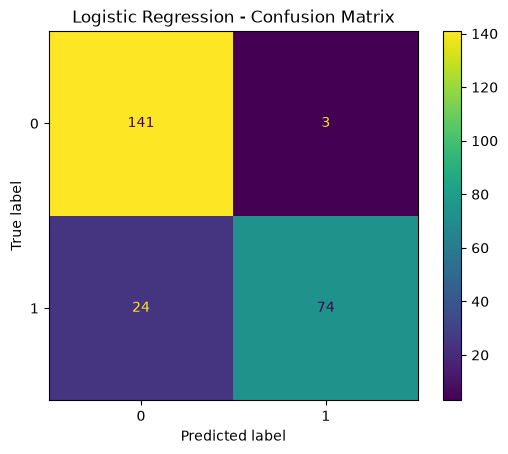

In [122]:
logistic_regression_confusion_matrix = confusion_matrix(y_test, logistic_regression_predictions)

ConfusionMatrixDisplay(confusion_matrix=logistic_regression_confusion_matrix).plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

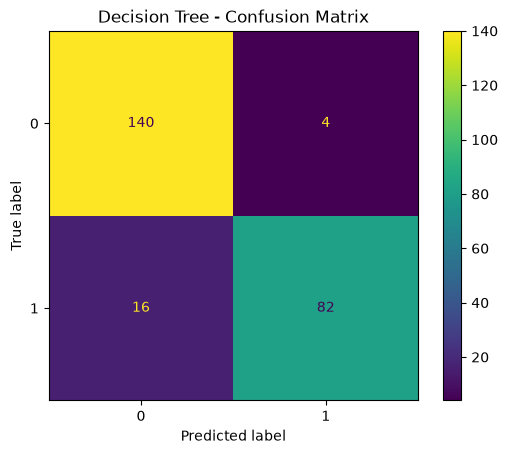

In [123]:
decision_tree_confusion_matrix = confusion_matrix(y_test, decision_tree_predictions)

ConfusionMatrixDisplay(confusion_matrix=decision_tree_confusion_matrix).plot()
plt.title("Decision Tree - Confusion Matrix")
plt.show()

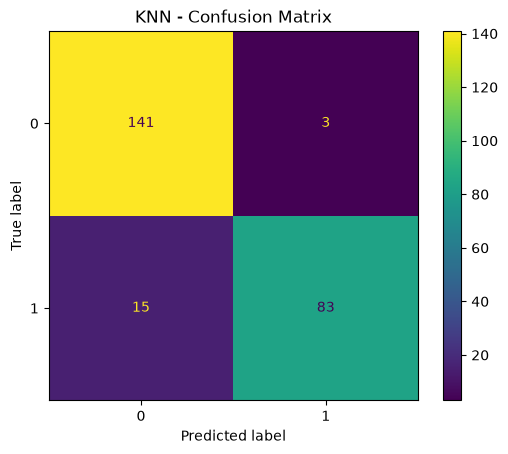

In [124]:
knn_confusion_matrix = confusion_matrix(y_test, knn_predictions)

ConfusionMatrixDisplay(confusion_matrix=knn_confusion_matrix).plot()
plt.title("KNN - Confusion Matrix")
plt.show()

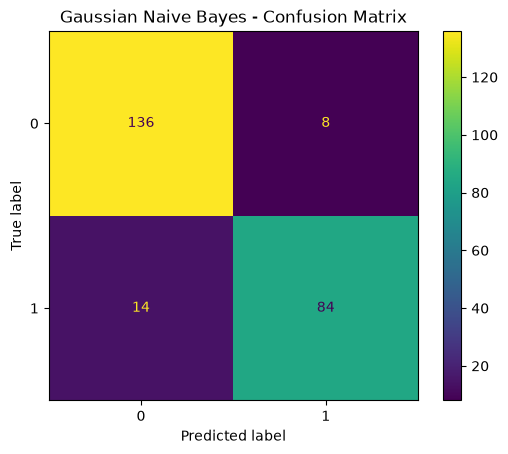

In [125]:
naive_bayes_confusion_matrix = confusion_matrix(y_test, naive_bayes_predictions)

ConfusionMatrixDisplay(confusion_matrix=naive_bayes_confusion_matrix).plot()
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

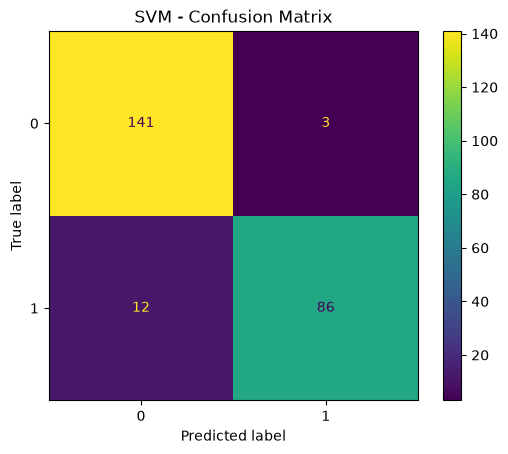

In [126]:
svm_confusion_matrix = confusion_matrix(y_test, svm_predictions)

ConfusionMatrixDisplay(confusion_matrix=svm_confusion_matrix).plot()
plt.title("SVM - Confusion Matrix")
plt.show()

In [127]:
print("Logistic Regression Classification Report")
print(classification_report(y_test, logistic_regression_predictions))

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.85      0.98      0.91       144
           1       0.96      0.76      0.85        98

    accuracy                           0.89       242
   macro avg       0.91      0.87      0.88       242
weighted avg       0.90      0.89      0.89       242



In [128]:
print("Decision Tree Classification Report")
print(classification_report(y_test, decision_tree_predictions))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       144
           1       0.95      0.84      0.89        98

    accuracy                           0.92       242
   macro avg       0.93      0.90      0.91       242
weighted avg       0.92      0.92      0.92       242



In [129]:
print("KNN Classification Report")
print(classification_report(y_test, knn_predictions))

KNN Classification Report
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       144
           1       0.97      0.85      0.90        98

    accuracy                           0.93       242
   macro avg       0.93      0.91      0.92       242
weighted avg       0.93      0.93      0.92       242



In [130]:
print("Gaussian Naive Bayes Classification Report")
print(classification_report(y_test, naive_bayes_predictions))

Gaussian Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.91      0.94      0.93       144
           1       0.91      0.86      0.88        98

    accuracy                           0.91       242
   macro avg       0.91      0.90      0.90       242
weighted avg       0.91      0.91      0.91       242



In [131]:
print("SVM Classification Report")
print(classification_report(y_test, svm_predictions))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.92      0.98      0.95       144
           1       0.97      0.88      0.92        98

    accuracy                           0.94       242
   macro avg       0.94      0.93      0.93       242
weighted avg       0.94      0.94      0.94       242



# Save Trained Models

In [133]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(logistic_regression_model, "models/logistic_regression.pkl")
joblib.dump(decision_tree_model, "models/decision_tree.pkl")
joblib.dump(knn_model, "models/knn.pkl")
joblib.dump(naive_bayes_model, "models/naive_bayes.pkl")
joblib.dump(svm_model, "models/svm.pkl")

joblib.dump(feature_scaler, "models/feature_scaler.pkl")
joblib.dump(label_encoders, "models/label_encoders.pkl")

print("All models and preprocessing objects saved successfully in models/!")
print("Saved files in models/:")
print(os.listdir("models"))


All models and preprocessing objects saved successfully in models/!
Saved files in models/:
['svm.pkl', 'decision_tree.pkl', 'knn.pkl', '.gitkeep', 'logistic_regression.pkl', 'label_encoders.pkl', 'naive_bayes.pkl', 'feature_scaler.pkl']


In [134]:
test_data = lung_cancer.iloc[test_indices].copy()

test_data.to_csv("test_data.csv", index=False)

print("Test dataset exported successfully!")
print("Test dataset shape:", test_data.shape)
print("\nTest dataset preview:")
display(test_data.head())

Test dataset exported successfully!
Test dataset shape: (242, 16)

Test dataset preview:


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
5,F,75,1,2,1,1,2,2,2,2,1,2,2,1,1,YES
16,M,75,2,1,1,1,2,1,2,2,2,2,2,1,2,YES
17,M,57,2,2,2,2,2,1,1,1,2,1,1,2,2,YES


In [135]:
print("File exists:", os.path.exists("test_data.csv"))
print("Number of records:", len(test_data))
print("Columns:", test_data.columns.tolist())

File exists: True
Number of records: 242
Columns: ['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']
